[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DANIFUZZY1975/estadistica-descriptiva-python/blob/main/notebooks/05_peliculas.ipynb)

# 🎬 ¿Qué películas compraría una plataforma de streaming? Estadística descriptiva con 10.000 películas

**Estadística Descriptiva · 1.º Grado en Ciencia de Datos · UCM**

### 💼 El encargo
Trabajáis en el equipo de datos de una plataforma de streaming. La dirección va a comprar los derechos de varios cientos de
películas y os pregunta:
- ¿Qué **géneros** compramos? ¿Los mejor **valorados** o los más **vistos**? ¿Es lo mismo?
- ¿**Clásicos** o películas **recientes**?
- ¿Merece la pena comprar un **remake** si ya tenemos la original?

Los datos son las 10.000 películas mejor valoradas de la web *The Movie Database* (TMDB) con al menos 200 votos:
título, géneros, fecha de estreno, **nota media** de los usuarios (0–10), **número de votos** y **popularidad**
(un índice de TMDB que mide cuánto se está buscando y viendo la película *ahora*).

**Plan de trabajo (2 sesiones de 2 h):**
- 🕐 Sesión 1 · Limpieza, géneros y una variable: nota y popularidad (apartados 1–4)
- 🕐 Sesión 2 · Comparar grupos, épocas, relaciones entre variables y el informe para la dirección (5–8)

In [1]:
# ============================================================
# 0. Librerías y estilo de los gráficos
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}" if v != 0 and abs(v) < 0.01 else f"{v:,.3f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.titleweight": "bold"})
AZUL, NARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"

# Los datos están en el repositorio de GitHub: así no hay que subir nada a Colab
URL_DATOS = "https://raw.githubusercontent.com/DANIFUZZY1975/estadistica-descriptiva-python/main/data/"

---
# 🕐 Sesión 1 de 2 · Limpieza, géneros y una variable
**Objetivos:** preparar los datos (fechas, listas dentro de una columna), frecuencias de una variable con varias categorías por fila,
posición, dispersión y forma de la nota y de la popularidad, atípicos.
**Apartados:** 1 a 4 · **Duración orientativa:** 2 horas

## 1. Carga y limpieza

In [2]:
pelis = pd.read_csv(URL_DATOS + "peliculas.csv")
print("Dimensiones:", pelis.shape)
pelis.head()

Dimensiones: (10000, 9)


,Unnamed: 0,id,genre_ids,title,overview,popularity,release_date,vote_average,vote_count
0,0,238,"[18, 80]",The Godfather,"Spanning the years 1945 to 1955, a chronicle o...",119.438,1972-03-14,8.700,18448
1,1,278,"[18, 80]",The Shawshank Redemption,Framed in the 1940s for the double murder of h...,90.415,1994-09-23,8.700,24376
2,2,240,"[18, 80]",The Godfather Part II,In the continuing saga of the Corleone crime f...,70.637,1974-12-20,8.600,11144
3,3,424,"[18, 36, 10752]",Schindler's List,The true story of how businessman Oskar Schind...,48.096,1993-12-15,8.600,14421
4,4,19404,"[35, 18, 10749]",Dilwale Dulhania Le Jayenge,"Raj is a rich, carefree, happy-go-lucky second...",26.588,1995-10-20,8.600,4225


In [3]:
pelis.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0    10000 non-null  int64  
 1   id            10000 non-null  int64  
 2   genre_ids     10000 non-null  str    
 3   title         10000 non-null  str    
 4   overview      9998 non-null   str    
 5   popularity    10000 non-null  float64
 6   release_date  10000 non-null  str    
 7   vote_average  10000 non-null  float64
 8   vote_count    10000 non-null  int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 703.3 KB


Tres cosas que arreglar:
1. `Unnamed: 0` es un índice que se guardó por error al exportar: fuera.
2. `release_date` es **texto**; la convertimos en fecha y sacamos el **año**.
3. `genre_ids` parece una lista (`[18, 80]`), pero en realidad es **texto** con corchetes. Hay que convertirlo en una lista de verdad
   y traducir los códigos a nombres de género.

In [4]:
pelis = pelis.drop(columns=["Unnamed: 0"])
pelis["fecha"] = pd.to_datetime(pelis["release_date"])
pelis["año"] = pelis["fecha"].dt.year
print(type(pelis.loc[0, "genre_ids"]), "->", pelis.loc[0, "genre_ids"])

<class 'str'> -> [18, 80]


In [5]:
# Códigos de género de TMDB
generos_tmdb = {28: "Acción", 12: "Aventura", 16: "Animación", 35: "Comedia", 80: "Crimen", 99: "Documental",
                18: "Drama", 10751: "Familiar", 14: "Fantasía", 36: "Historia", 27: "Terror", 10402: "Música",
                9648: "Misterio", 10749: "Romance", 878: "Ciencia ficción", 10770: "Película de TV",
                53: "Suspense", 10752: "Bélica", 37: "Western"}

# "[18, 80]" -> quitamos los corchetes, separamos por comas y traducimos cada número
pelis["generos"] = (pelis["genre_ids"].str.strip("[]").str.split(",")
                    .apply(lambda lista: [generos_tmdb[int(c)] for c in lista if c.strip() != ""]))
pelis["n_generos"] = pelis["generos"].str.len()
pelis[["title", "año", "genre_ids", "generos", "n_generos"]].head()

,title,año,genre_ids,generos,n_generos
0,The Godfather,1972,"[18, 80]","[Drama, Crimen]",2
1,The Shawshank Redemption,1994,"[18, 80]","[Drama, Crimen]",2
2,The Godfather Part II,1974,"[18, 80]","[Drama, Crimen]",2
3,Schindler's List,1993,"[18, 36, 10752]","[Drama, Historia, Bélica]",3
4,Dilwale Dulhania Le Jayenge,1995,"[35, 18, 10749]","[Comedia, Drama, Romance]",3


### ¿Hay películas repetidas?

In [6]:
print("Mismo id repetido:", pelis["id"].duplicated().sum())
print("Mismo título repetido:", pelis["title"].duplicated().sum())
pelis[pelis["title"].duplicated(keep=False)].sort_values(["title", "año"])[["title", "año", "vote_average", "vote_count"]].head(10)

Mismo id repetido: 0
Mismo título repetido: 335


,title,año,vote_average,vote_count
5,12 Angry Men,1957,8.500,7529
1029,12 Angry Men,1997,7.600,276
2626,3:10 to Yuma,1957,7.200,304
2684,3:10 to Yuma,2007,7.200,3215
2947,9,2005,7.100,230
4109,9,2009,6.900,3234
1938,A Christmas Carol,1984,7.400,294
4358,A Christmas Carol,2009,6.900,4142
3136,A Star Is Born,1954,7.100,258
1408,A Star Is Born,2018,7.500,11001


🤔 No hay ids repetidos, pero sí **335 filas con un título repetido** (305 títulos distintos). ¿Son errores? No: muchos son **remakes** (*12 Angry Men* de 1957 y de 1997)
y otros, películas distintas que comparten título (*9*). Lo aprovecharemos en el apartado 8.

## 2. Variable cualitativa con varias categorías por fila: los géneros
Una película puede tener varios géneros a la vez. ¿Cuántos tiene cada película?

In [7]:
tabla_ng = pelis["n_generos"].value_counts().sort_index().to_frame("n_i")
tabla_ng["f_i_%"] = 100 * tabla_ng["n_i"] / len(pelis)
tabla_ng["F_i_%"] = tabla_ng["f_i_%"].cumsum()
tabla_ng

,n_i,f_i_%,F_i_%
n_generos,,,
0,3,0.030,0.030
1,1610,16.100,16.130
2,3155,31.550,47.680
3,3505,35.050,82.730
4,1297,12.970,95.700
5,355,3.550,99.250
6,65,0.650,99.900
7,9,0.090,99.990
9,1,0.010,100.000


Para contar géneros usamos `explode()`: convierte cada película con 3 géneros en **3 filas**, una por género.

In [8]:
por_genero = pelis.explode("generos").dropna(subset=["generos"]).reset_index(drop=True)
print(f"De {len(pelis)} películas pasamos a {len(por_genero)} filas película-género")
print("(las 3 películas sin ningún género se quedan fuera; reset_index numera de nuevo las filas, que se habían repetido)")
frec_gen = por_genero["generos"].value_counts().to_frame("n_i")
frec_gen["% de películas"] = 100 * frec_gen["n_i"] / len(pelis)
frec_gen

De 10000 películas pasamos a 25860 filas película-género
(las 3 películas sin ningún género se quedan fuera; reset_index numera de nuevo las filas, que se habían repetido)


,n_i,% de películas
generos,,
Drama,4782,47.820
Comedia,3609,36.090
Suspense,2517,25.170
Acción,2175,21.750
Romance,1762,17.620
Aventura,1573,15.730
Crimen,1491,14.910
Terror,1220,12.200
Familiar,1161,11.610


🤔 Si sumas la columna `% de películas`, ¿da 100 %? ¿Por qué no? (Una película cuenta en varios géneros.)
Por eso las frecuencias relativas de una variable **multirrespuesta** no suman 1.

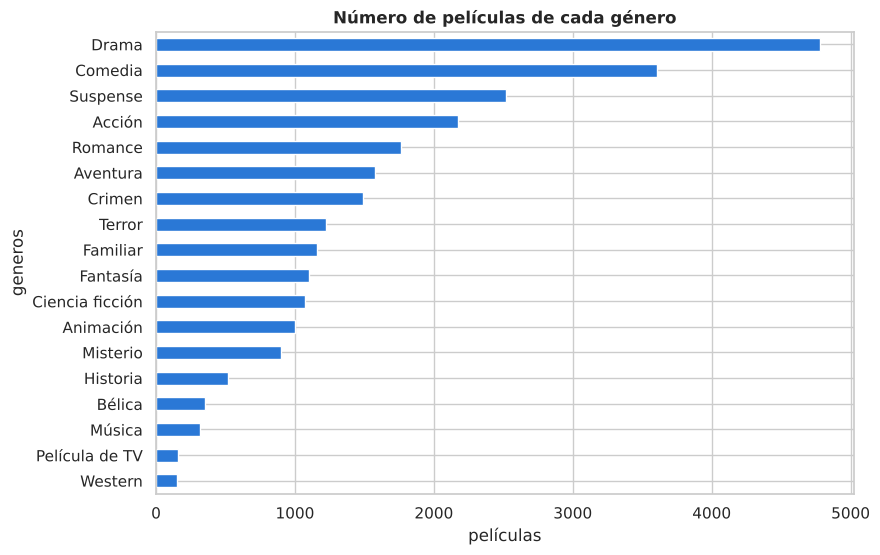

In [9]:
ax = frec_gen["n_i"].sort_values().plot.barh(color=AZUL, figsize=(9, 6))
ax.set_title("Número de películas de cada género"); ax.set_xlabel("películas")
plt.show()

## 3. La nota media de los usuarios (`vote_average`)

In [10]:
x = pelis["vote_average"]
print(f"Media    : {x.mean():.3f}")
print(f"Mediana  : {x.median():.3f}")
print(f"Moda     : {x.mode().tolist()}")
print(f"Mínimo   : {x.min()}   Máximo: {x.max()}")
print(f"Desv. típica: {x.std():.3f}   IQR: {x.quantile(0.75) - x.quantile(0.25):.2f}")
print(f"Asimetría: {x.skew():.3f}   Curtosis: {x.kurt():.3f}")

Media    : 6.772
Mediana  : 6.700
Moda     : [6.5]
Mínimo   : 5.7   Máximo: 8.7
Desv. típica: 0.637   IQR: 0.90
Asimetría: 0.297   Curtosis: -0.659


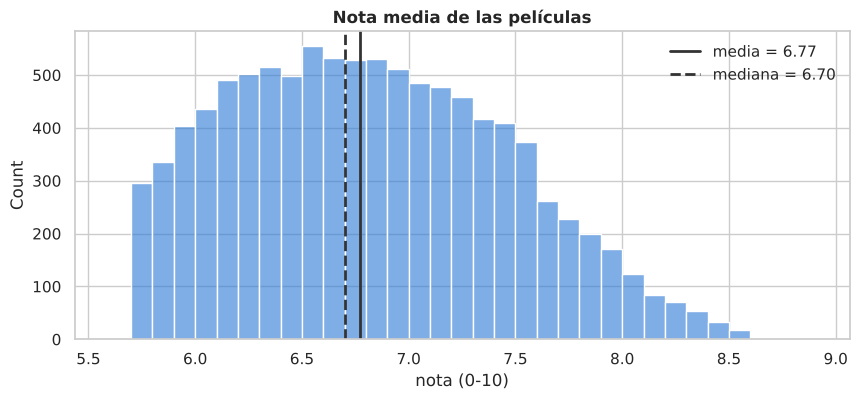

In [11]:
sns.histplot(x, bins=np.arange(5.6, 8.9, 0.1), color=AZUL, alpha=0.6)
plt.axvline(x.mean(), color="#333333", lw=2, label=f"media = {x.mean():.2f}")
plt.axvline(x.median(), color="#333333", ls="--", lw=2, label=f"mediana = {x.median():.2f}")
plt.title("Nota media de las películas"); plt.xlabel("nota (0-10)"); plt.legend(frameon=False)
plt.show()

🤔 **¿No hay ninguna película con menos de un 5,7?** El histograma está **cortado** a la izquierda. ¿Es que no existen películas malas?
No: este dataset son las 10.000 películas **mejor valoradas**. Es una **muestra seleccionada**, no "todas las películas".
Cualquier conclusión vale solo para este catálogo de películas buenas. Fíjate también en que la nota tiene muy poca dispersión
(desviación típica 0,64): casi todas están entre 6 y 7,5.

Las mejor y peor valoradas del catálogo:

In [12]:
pd.concat([pelis.nlargest(5, "vote_average"), pelis.nsmallest(5, "vote_average")])[["title", "año", "vote_average", "vote_count"]]

,title,año,vote_average,vote_count
0,The Godfather,1972,8.700,18448
1,The Shawshank Redemption,1994,8.700,24376
2,The Godfather Part II,1974,8.600,11144
3,Schindler's List,1993,8.600,14421
4,Dilwale Dulhania Le Jayenge,1995,8.600,4225
9704,Samson,2018,5.700,215
9705,War on Everyone,2016,5.700,372
9706,The Three Stooges,2012,5.700,505
9707,Man of the House,2005,5.700,425
9708,Tall Girl 2,2022,5.700,306


## 4. La popularidad: una variable muy asimétrica

In [13]:
p = pelis["popularity"]
print(f"Media    : {p.mean():.2f}")
print(f"Mediana  : {p.median():.2f}")
print(f"Máximo   : {p.max():.2f}")
print(f"Desv. típica: {p.std():.2f}  (¡mayor que la media!)   CV = {100 * p.std() / p.mean():.0f} %")
print(f"Asimetría: {p.skew():.2f}")

Media    : 21.55
Mediana  : 12.44
Máximo   : 4696.55
Desv. típica: 76.29  (¡mayor que la media!)   CV = 354 %
Asimetría: 34.38


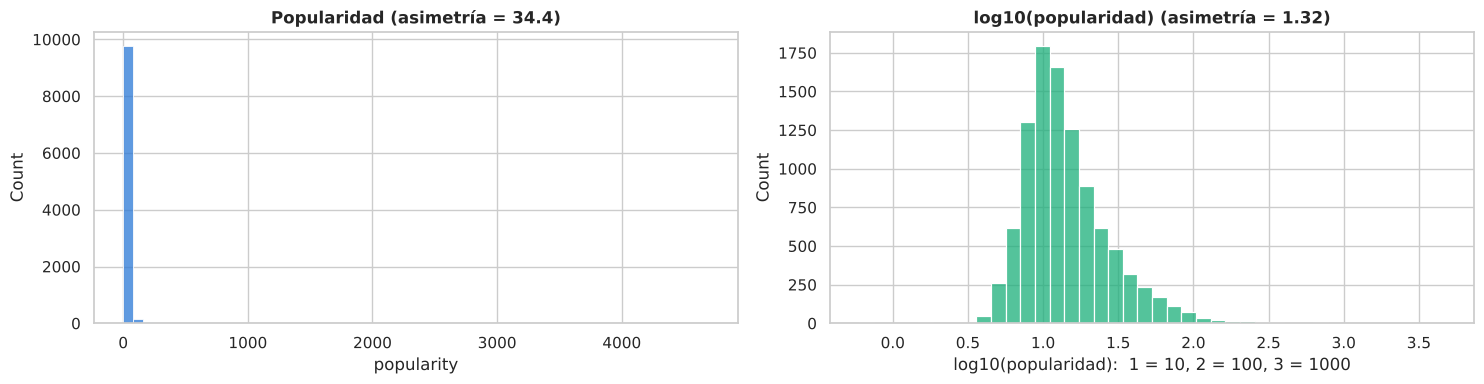

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(p, bins=60, color=AZUL, ax=axes[0])
axes[0].set_title(f"Popularidad (asimetría = {p.skew():.1f})")
sns.histplot(np.log10(p), bins=40, color=VERDE, ax=axes[1])
axes[1].set_title(f"log10(popularidad) (asimetría = {np.log10(p).skew():.2f})")
axes[1].set_xlabel("log10(popularidad):  1 = 10, 2 = 100, 3 = 1000")
plt.tight_layout(); plt.show()

🎯 La popularidad tiene una **cola larguísima** a la derecha: la media (21,5) casi duplica a la mediana (12,4). En una variable así,
la **media no representa** a la película típica. Con logaritmos la forma se vuelve mucho más manejable.

### Atípicos: ¿quién está tan por encima?

In [15]:
q1, q3 = p.quantile(0.25), p.quantile(0.75)
iqr = q3 - q1
ls = q3 + 1.5 * iqr
atipicas = pelis[p > ls]
print(f"Valla superior de Tukey: {ls:.1f} -> {len(atipicas)} películas atípicas ({100 * len(atipicas) / len(pelis):.1f} %)")
print("¿De qué año son las atípicas?")
print(atipicas["año"].value_counts().head(5).to_string())
pelis.nlargest(10, "popularity")[["title", "año", "popularity", "vote_average"]]

Valla superior de Tukey: 35.2 -> 964 películas atípicas (9.6 %)
¿De qué año son las atípicas?
año
2022    135
2023     80
2021     65
2019     45
2014     43


,title,año,popularity,vote_average
776,Elemental,2023,"4,696.546",7.800
16,Spider-Man: Across the Spider-Verse,2023,"2,517.658",8.500
3725,Heart of Stone,2023,"1,851.905",7.000
3302,No Hard Feelings,2023,"1,812.181",7.100
1686,Barbie,2023,"1,748.951",7.400
1463,Transformers: Rise of the Beasts,2023,"1,691.784",7.500
3620,Meg 2: The Trench,2023,"1,424.145",7.000
3754,The Flash,2023,"1,377.709",7.000
3997,Insidious: The Red Door,2023,"1,147.176",6.900
2176,Fast X,2023,"1,058.630",7.300


🤔 Las más populares son casi todas **estrenos recientes** (2023). La popularidad mide lo que se ve **ahora**, así que favorece
lo nuevo. Para la plataforma esto es importante: **un estreno es popular unos meses; un clásico bien valorado, durante años**.

### 🚀 Retos de la sesión 1
1. ¿Qué porcentaje de películas tiene **3 géneros o menos**? (usa la tabla de `n_generos`)
2. Calcula media, mediana y desviación típica del **número de votos** (`vote_count`). ¿Es simétrica? Dibuja su histograma con y sin logaritmos.
3. ¿Cuál es la película **más antigua** del catálogo? ¿Y la más reciente? ¿Cuántas hay de cada década? (pista: `(pelis["año"] // 10) * 10`)
4. Busca tu película favorita con `pelis[pelis["title"].str.contains("...")]`. ¿En qué percentil de nota está?

---
✅ **Fin de la sesión 1.**

---
# 🕐 Sesión 2 de 2 · Comparar grupos, épocas y relaciones
**Objetivos:** comparar géneros con `groupby`, sesgo de supervivencia, correlación y regresión (lineal y potencial)
con variables muy asimétricas, y redactar el informe para la dirección.
**Apartados:** 5 a 8 · **Duración orientativa:** 2 horas
> 💡 Si abres el notebook en una sesión nueva, ejecuta antes todas las celdas anteriores: menú *Entorno de ejecución → Ejecutar las celdas anteriores* (Ctrl+F8).

## 5. 🏆 ¿Qué género compramos? Valoración frente a popularidad

In [16]:
tabla_gen = (por_genero.groupby("generos")
               .agg(n=("title", "size"),
                    nota_media=("vote_average", "mean"),
                    nota_mediana=("vote_average", "median"),
                    popularidad_mediana=("popularity", "median"),
                    votos_mediana=("vote_count", "median"))
               .sort_values("nota_media", ascending=False))
tabla_gen.round(2).style.background_gradient(subset=["nota_media"], cmap="Blues").background_gradient(subset=["popularidad_mediana"], cmap="Oranges")

,n,nota_media,nota_mediana,popularidad_mediana,votos_mediana
generos,,,,,
Bélica,353,7.100000,7.100000,12.640000,596.000000
Historia,520,7.070000,7.100000,11.820000,622.000000
Animación,1004,7.060000,7.100000,17.720000,600.500000
Western,151,6.970000,7.000000,13.370000,555.000000
Drama,4782,6.930000,6.900000,11.250000,560.500000
Música,313,6.920000,6.900000,11.750000,440.000000
Película de TV,156,6.890000,6.800000,10.710000,337.000000
Fantasía,1101,6.840000,6.800000,16.690000,812.000000
Romance,1762,6.820000,6.800000,11.360000,550.500000


🤔 ¿Por qué usamos la **mediana** de la popularidad y no la media? (Recuerda el apartado 4.)

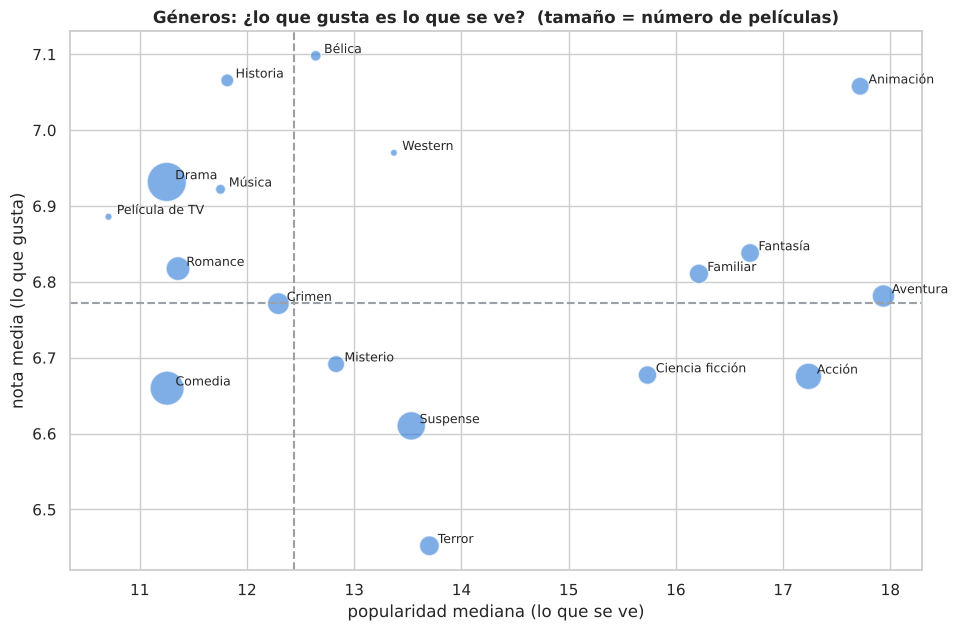

In [17]:
fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(tabla_gen["popularidad_mediana"], tabla_gen["nota_media"], s=tabla_gen["n"] / 6, color=AZUL, alpha=0.6, edgecolor="white")
for genero, f in tabla_gen.iterrows():
    ax.annotate(genero, (f["popularidad_mediana"], f["nota_media"]), xytext=(6, 2), textcoords="offset points", fontsize=9)
ax.axvline(pelis["popularity"].median(), color="#9aa0a6", ls="--")
ax.axhline(pelis["vote_average"].mean(), color="#9aa0a6", ls="--")
ax.set_xlabel("popularidad mediana (lo que se ve)"); ax.set_ylabel("nota media (lo que gusta)")
ax.set_title("Géneros: ¿lo que gusta es lo que se ve?  (tamaño = número de películas)")
plt.show()

🎯 **Cuatro cuadrantes, cuatro estrategias:**
- **Arriba a la derecha** (gusta y se ve): **Animación**, Fantasía, Familiar. El género "seguro".
- **Arriba a la izquierda** (gusta, pero se ve poco): Bélica, Historia, Drama, Western. Prestigio barato: catálogo de fondo.
- **Abajo a la derecha** (se ve mucho aunque guste menos): Acción, Aventura, Ciencia ficción. Atraen público.
- **Abajo a la izquierda**: la Comedia, con muchísimas películas, nota baja y poca popularidad.
- Y en medio, Suspense, Misterio y **Terror**: algo más vistos que la mediana, pero peor valorados. El Terror es el género peor
  valorado… y aun así se ve más que el Drama.

Lo que **gusta** y lo que **se ve** no son lo mismo. La plataforma tiene que decidir qué quiere.

### ¿Los géneros son homogéneos? Dispersión por grupo

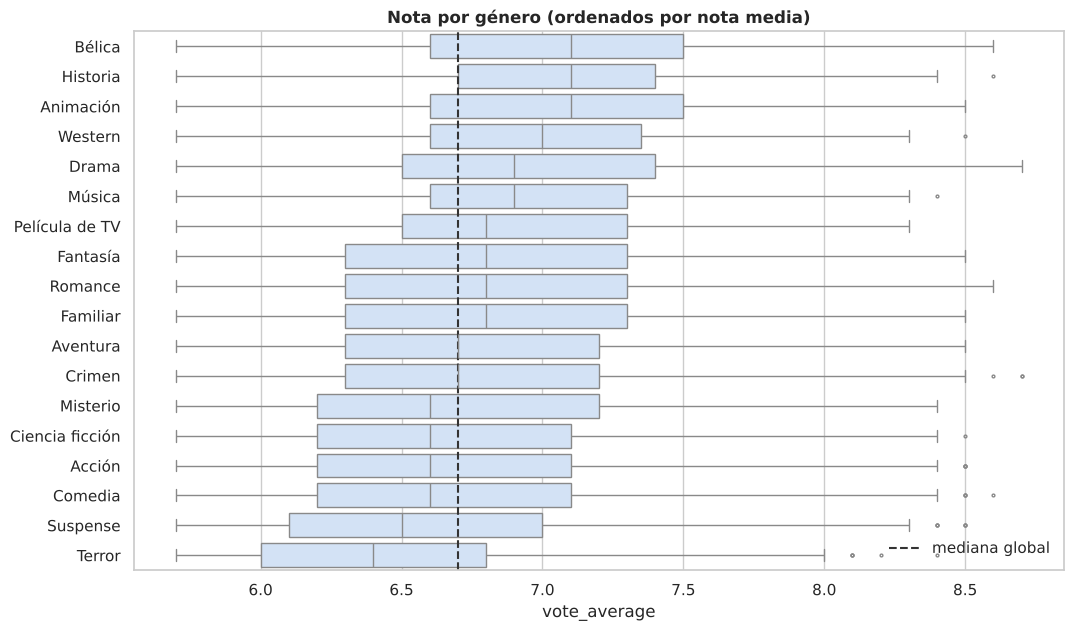

In [18]:
orden = tabla_gen.index
fig, ax = plt.subplots(figsize=(12, 7))
sns.boxplot(data=por_genero, y="generos", x="vote_average", order=orden, color="#cde2fb", fliersize=2, ax=ax)
ax.axvline(pelis["vote_average"].median(), color="#333333", ls="--", label="mediana global")
ax.set_title("Nota por género (ordenados por nota media)"); ax.set_ylabel(""); ax.legend(frameon=False)
plt.show()

## 6. ¿Clásicos o recientes? El sesgo de supervivencia

In [19]:
pelis["decada"] = (pelis["año"] // 10) * 10
por_decada = pelis.groupby("decada").agg(n=("title", "size"), nota_media=("vote_average", "mean"),
                                         nota_mediana=("vote_average", "median"),
                                         popularidad_mediana=("popularity", "median"))
por_decada.round(2)

,n,nota_media,nota_mediana,popularidad_mediana
decada,,,,
1890,1,6.900,6.900,5.140
1900,2,7.450,7.450,9.660
1910,5,6.900,7.100,6.870
1920,27,7.690,7.800,9.160
1930,63,7.350,7.500,8.960
1940,110,7.390,7.500,9.560
1950,186,7.430,7.400,10.860
1960,284,7.340,7.400,10.530
1970,409,7.040,7.100,10.900


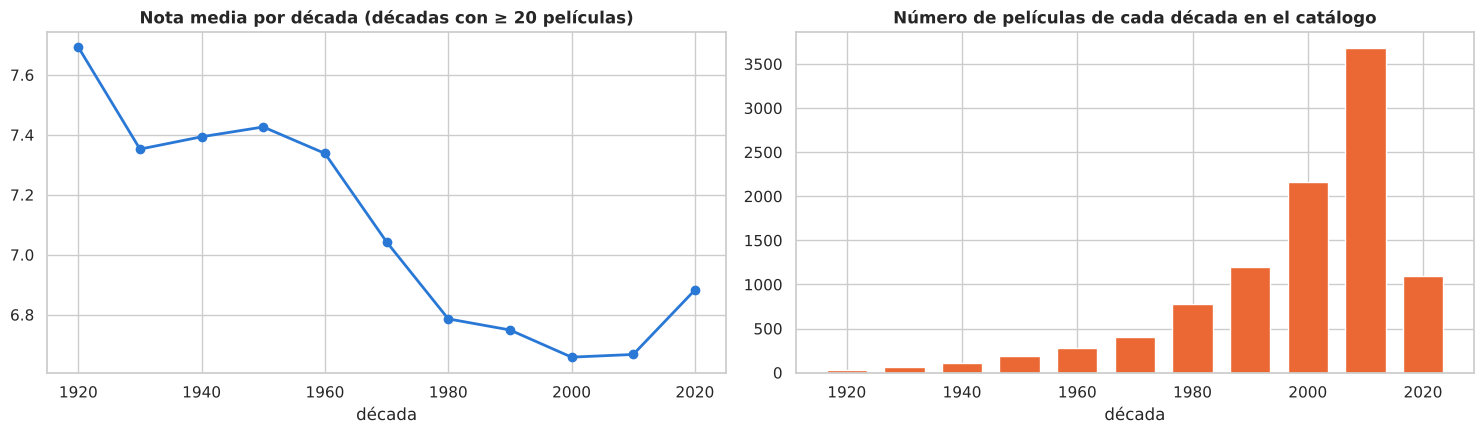

In [20]:
d = por_decada[por_decada["n"] >= 20]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(d.index, d["nota_media"], marker="o", color=AZUL, lw=2)
axes[0].set_title("Nota media por década (décadas con ≥ 20 películas)"); axes[0].set_xlabel("década")
axes[1].bar(d.index, d["n"], width=7, color=NARANJA)
axes[1].set_title("Número de películas de cada década en el catálogo"); axes[1].set_xlabel("década")
plt.tight_layout(); plt.show()

🤔 **¿El cine de antes era mejor?** Las películas de los años 20 a 60 tienen notas más altas… pero hay **muchas menos**.
De los años 50 sobreviven en el catálogo 186 películas; de los 2010, casi 3.700. De la época antigua **solo ha llegado hasta hoy lo mejor**:
las películas malas de 1950 nadie las vota ya y no pasan el filtro de 200 votos. Esto es el **sesgo de supervivencia**.
No podemos concluir que el cine antiguo fuera mejor: estamos comparando **lo mejor de antes** con **casi todo lo de ahora**.

🤔 ¿Y por qué **sube** la nota en los años 2020? Pista: las películas recién estrenadas las votan primero sus fans.

## 7. Relaciones entre variables: ¿más votos = más popularidad?

In [21]:
print("Correlación votos–popularidad              :", round(pelis["vote_count"].corr(pelis["popularity"]), 3))
print("Correlación log(votos)–log(popularidad)    :", round(np.log(pelis["vote_count"]).corr(np.log(pelis["popularity"])), 3))
print("Correlación nota–popularidad               :", round(pelis["vote_average"].corr(pelis["popularity"]), 3))
print("Correlación nota–log(votos)                :", round(pelis["vote_average"].corr(np.log(pelis["vote_count"])), 3))

Correlación votos–popularidad              : 0.14
Correlación log(votos)–log(popularidad)    : 0.603
Correlación nota–popularidad               : 0.092
Correlación nota–log(votos)                : 0.226


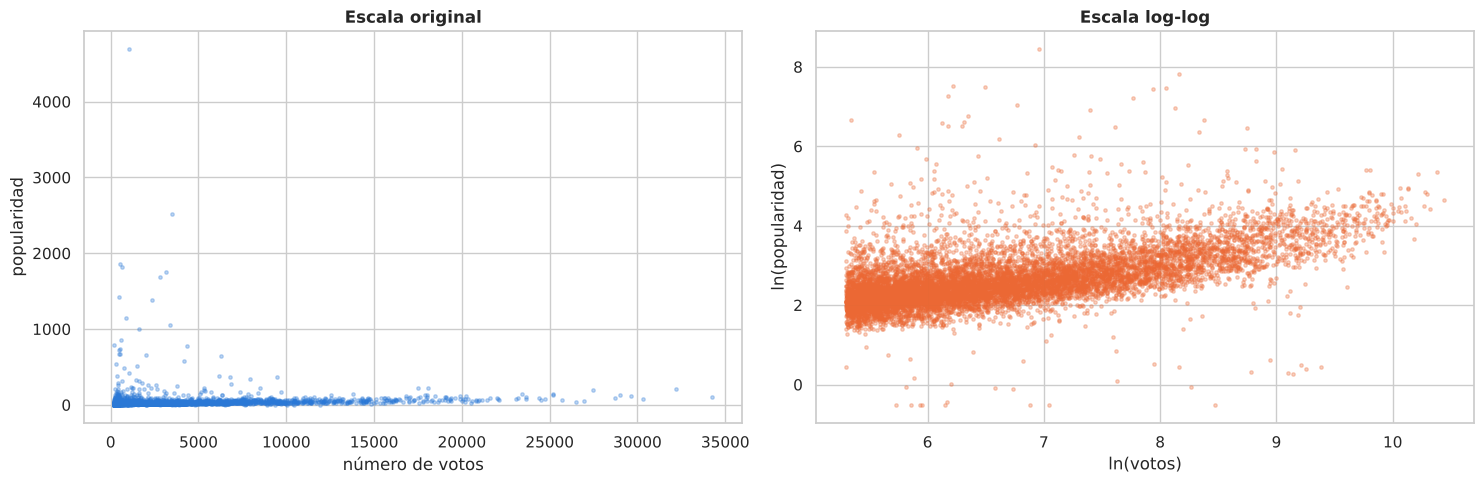

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(pelis["vote_count"], pelis["popularity"], s=6, alpha=0.3, color=AZUL)
axes[0].set_xlabel("número de votos"); axes[0].set_ylabel("popularidad"); axes[0].set_title("Escala original")
axes[1].scatter(np.log(pelis["vote_count"]), np.log(pelis["popularity"]), s=6, alpha=0.3, color=NARANJA)
axes[1].set_xlabel("ln(votos)"); axes[1].set_ylabel("ln(popularidad)"); axes[1].set_title("Escala log-log")
plt.tight_layout(); plt.show()

🎯 En escala original la correlación es solo 0,14: la nube está aplastada contra los ejes por unas pocas películas enormes.
En escala **log-log** la relación aparece clara ($r \approx 0{,}60$). Con variables tan asimétricas, el coeficiente de Pearson
en escala original engaña. Ajustemos un modelo **potencial** $\text{popularidad} = a \cdot \text{votos}^b$:

popularidad = 1.105 · votos^0.382     R² (en logaritmos) = 0.363
Si una película tiene el doble de votos, su popularidad se multiplica por 2^0.382 = 1.30


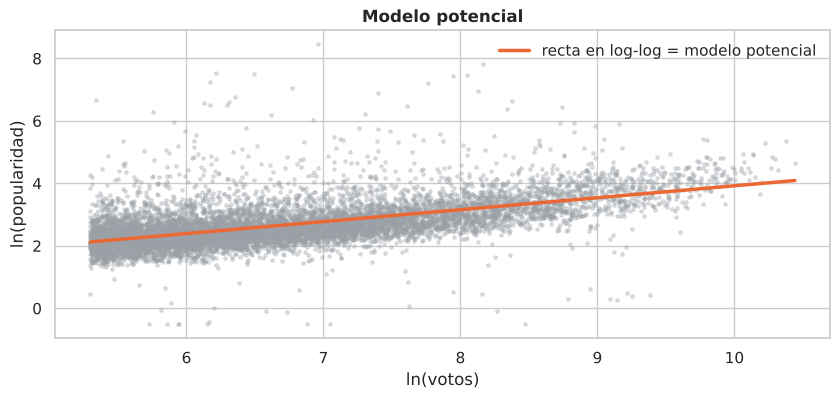

In [23]:
x, y = pelis["vote_count"], pelis["popularity"]
lx, ly = np.log(x), np.log(y)

b_pot = ((lx - lx.mean()) * (ly - ly.mean())).mean() / ((lx - lx.mean()) ** 2).mean()
a_pot = np.exp(ly.mean() - b_pot * lx.mean())
r2_log = 1 - ((ly - (np.log(a_pot) + b_pot * lx)) ** 2).sum() / ((ly - ly.mean()) ** 2).sum()
print(f"popularidad = {a_pot:.3f} · votos^{b_pot:.3f}     R² (en logaritmos) = {r2_log:.3f}")
print(f"Si una película tiene el doble de votos, su popularidad se multiplica por 2^{b_pot:.3f} = {2 ** b_pot:.2f}")

xs = np.linspace(np.log(x.min()), np.log(x.max()), 100)
plt.scatter(lx, ly, s=6, alpha=0.3, color="#9aa0a6")
plt.plot(xs, np.log(a_pot) + b_pot * xs, color=NARANJA, lw=2.5, label="recta en log-log = modelo potencial")
plt.xlabel("ln(votos)"); plt.ylabel("ln(popularidad)"); plt.legend(frameon=False); plt.title("Modelo potencial")
plt.show()

🤔 Y la **nota** casi no tiene relación con la popularidad ($r \approx 0{,}09$). **Que una película sea buena no hace que se vea más.**

## 8. ¿Compramos remakes? Original frente a nueva versión
Tomamos los títulos que aparecen más de una vez y comparamos la **primera** versión con la **última**.
(Ojo: algunos títulos repetidos no son remakes sino películas distintas con el mismo nombre. Es una aproximación.)

In [24]:
repetidas = pelis[pelis["title"].duplicated(keep=False)].sort_values(["title", "año"])
versiones = repetidas.groupby("title").agg(n_versiones=("año", "size"),
                                           año_original=("año", "first"), nota_original=("vote_average", "first"),
                                           año_ultima=("año", "last"), nota_ultima=("vote_average", "last"))
versiones["diferencia"] = versiones["nota_original"] - versiones["nota_ultima"]
print(f"Títulos con varias versiones: {len(versiones)}")
print(f"La original tiene MÁS nota en el {100 * (versiones['diferencia'] > 0).mean():.0f} % de los casos")
print(f"Diferencia media: {versiones['diferencia'].mean():+.2f} puntos   |   mediana: {versiones['diferencia'].median():+.2f}")
versiones.sort_values("diferencia", ascending=False).head(8)

Títulos con varias versiones: 305
La original tiene MÁS nota en el 63 % de los casos
Diferencia media: +0.29 puntos   |   mediana: +0.30


,n_versiones,año_original,nota_original,año_ultima,nota_ultima,diferencia
title,,,,,,
Oldboy,2,2003,8.300,2013,5.900,2.400
The Kid,3,1921,8.200,2019,5.800,2.400
Ben-Hur,2,1959,7.900,2016,5.700,2.200
Solaris,2,1972,7.900,2002,5.900,2.000
Planet of the Apes,2,1968,7.600,2001,5.700,1.900
Ghost in the Shell,2,1995,7.900,2017,6.100,1.800
The Vanishing,3,1988,7.500,2019,5.700,1.800
The Thing,2,1982,8.000,2011,6.200,1.800


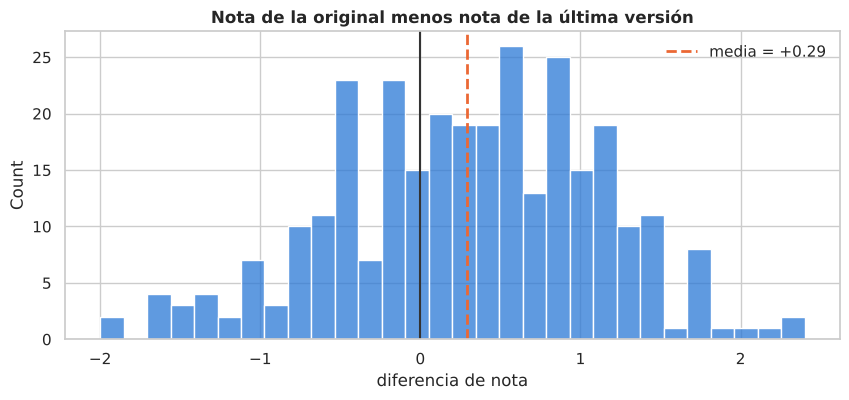

In [25]:
sns.histplot(versiones["diferencia"], bins=30, color=AZUL)
plt.axvline(0, color="#333333", lw=1.5)
plt.axvline(versiones["diferencia"].mean(), color=NARANJA, lw=2, ls="--", label=f"media = {versiones['diferencia'].mean():+.2f}")
plt.title("Nota de la original menos nota de la última versión"); plt.xlabel("diferencia de nota"); plt.legend(frameon=False)
plt.show()

🤔 La original suele estar mejor valorada (en torno a 6 de cada 10 veces), pero ¡cuidado! Ya hemos visto que las películas antiguas
que siguen en el catálogo son **supervivientes**. ¿Puede eso explicar parte de la diferencia?

## 📝 El informe para la dirección
Con lo que hemos visto, redactad (en 5 líneas) vuestra recomendación de compra. Algunas ideas de lo que los datos dicen:
1. **Lo que gusta y lo que se ve no coinciden.** La Animación es el único género grande que destaca en las dos cosas.
2. **La popularidad es efímera y muy desigual**: unas pocas películas (los estrenos) se llevan la atención. La mediana, no la media,
   describe a la película típica.
3. **Los clásicos están bien valorados**, pero en parte por el sesgo de supervivencia: compradlos por su valor, no porque "antes se hiciera mejor cine".
4. **Los remakes suelen valorarse peor** que la original; si ya tenemos la original, el remake aporta poco en nota.
5. **Lo que no sabemos**: el precio de cada película, cuánto la ven nuestros usuarios… Sin esos datos no podemos calcular la rentabilidad.

### 🚀 Retos de la sesión 2
1. Repite la tabla de géneros quitando las películas posteriores a 2020. ¿Cambia el cuadrante de algún género?
2. ¿Qué género tiene la **mayor dispersión** de nota (desviación típica e IQR)? ¿Y la menor?
3. Calcula el porcentaje de películas de **Terror** en cada década. ¿Cada vez se hace más terror?
4. ¿Las películas con **más géneros** tienen más o menos nota? Calcula la nota media según `n_generos` (solo grupos con n ≥ 50).
5. Ajusta un modelo lineal para la nota en función de `ln(vote_count)`. ¿Cuánto vale el $R^2$? Interprétalo.

---
🏁 **Fin del notebook.**